Part 1 — Load & Explore the Data

Cell 1 — Imports (required in every notebook)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn import metrics

%matplotlib inline
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

Task 1: Load the dataset into a DataFrame and print its shape and column names

In [2]:
df = pd.read_csv('USA_Housing.csv')
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())

Shape: (5000, 7)
Columns: ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address']



Task 2: Display the first 5 rows, then run df.info() and df.describe()

In [3]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [5]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


Task 3: Check for missing values in every column

In [6]:
df.isnull().sum().sort_values(ascending=False)

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

Task 4: Drop the Address column — it isn't useful for a numeric regression model.

In [7]:
df = df.drop('Address', axis=1)
print(df.columns.tolist())

['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population', 'Price']


Task 5: Create a heatmap of the correlation between all numeric columns, including Price.

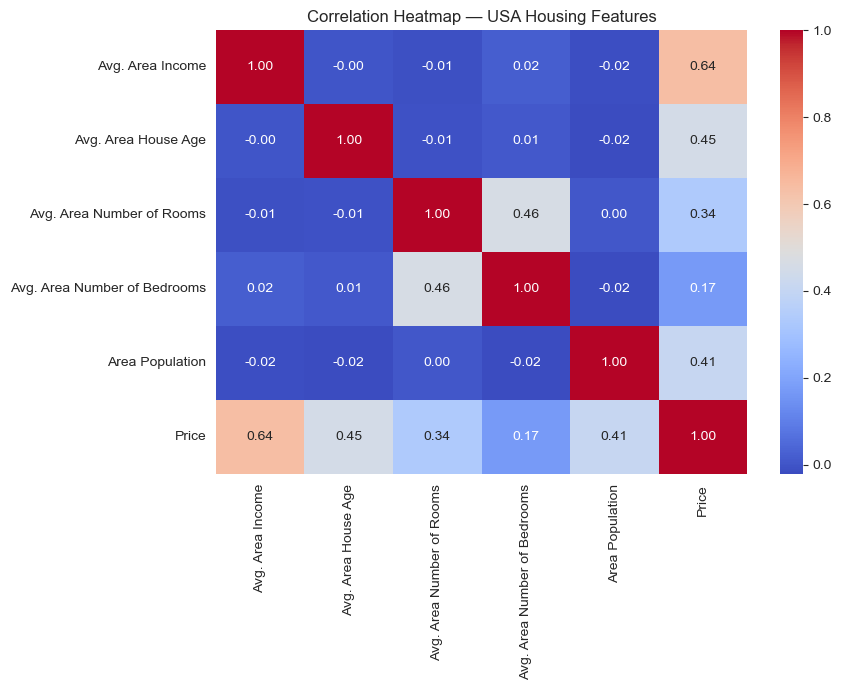

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap — USA Housing Features')
plt.tight_layout()
plt.show()

Observation Prompt — Part 1: In a Markdown cell, note which feature has the strongest
correlation with Price, and which has the weakest. What does that suggest about which features
will matter most for prediction?

In [9]:
df.corr()['Price'].sort_values(ascending=False)

Price                           1.000000
Avg. Area Income                0.639734
Avg. Area House Age             0.452543
Area Population                 0.408556
Avg. Area Number of Rooms       0.335664
Avg. Area Number of Bedrooms    0.171071
Name: Price, dtype: float64

I noticed Avg. Area Income has the highest correlation with Price (r = 0.64), while Avg. Area Number of Bedrooms has the lowest correlation with Price (r = 0.17). So going into the modeling step, I'd expect income to carry the most weight in predicting price.

Part 2 — Simple Linear Regression

Task 1: Select Avg. Area Income as X and Price as y.

In [10]:
X = df[['Avg. Area Income']]
y = df['Price']

Task 2: Split the data into training and test sets (80% train, 20% test).[0])


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)
print('Train size:', X_train.shape[0])
print('Test size:', X_test.shape[0])

Train size: 4000
Test size: 1000


Task 3: Create and fit a LinearRegression model on the training data.

In [12]:
model_simple = LinearRegression()
model_simple.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Task 4: Predict on the test set, then plot actual vs. predicted values as a scatter plot.

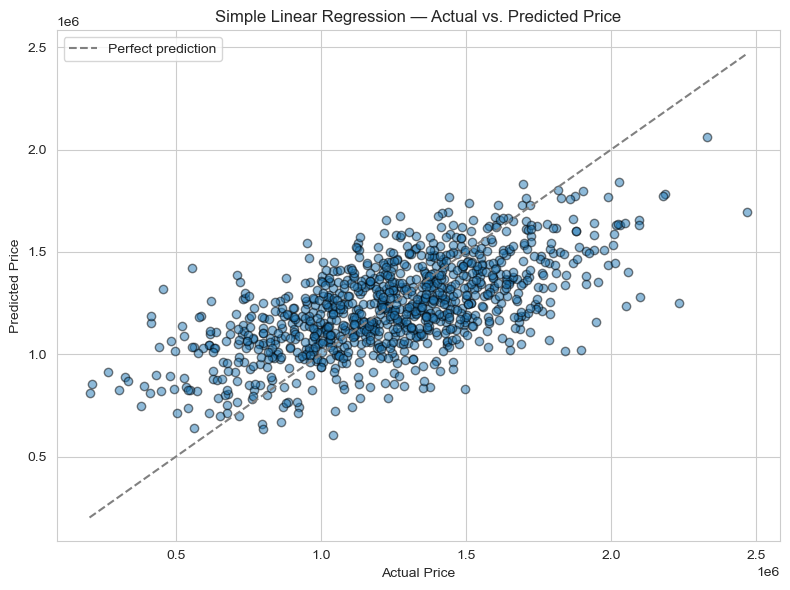

In [13]:
y_pred_simple = model_simple.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_simple, alpha=0.5, edgecolor='k')
lims = [min(y_test.min(), y_pred_simple.min()), max(y_test.max(), y_pred_simple.max())]
plt.plot(lims, lims, linestyle='--', color='gray', label='Perfect prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Simple Linear Regression — Actual vs. Predicted Price')
plt.legend()
plt.tight_layout()
plt.show()

Task 5: Print the model's coefficient and intercept.

In [14]:
print('Coefficient:', model_simple.coef_[0])
print('Intercept:', model_simple.intercept_)

Coefficient: 21.208906292657534
Intercept: -225053.70287170308


The coefficient (21.21) shows that for every extra `$1 in average area income, the model predicts the house price increases by about $21.21`. So areas with higher average income tend to have more expensive houses, and income has a fairly consistent effect on predicted price.

Observation Prompt — Part 2: In one or two sentences, explain: for every $1 increase in
average area income, how much does the predicted house price change, according to this
model?

`For every $1 increase in average area income, the model predicts a house price increase of about $21.21.`

Part 3 — Multiple Linear Regression


Task 1: Select all numeric feature columns (everything except Price) as X, and Price as y.


In [15]:
X_multi = df.drop('Price', axis=1)
y_multi = df['Price']

Task 2: Split into training and test sets (80/20), using the same random_state=42 as before.


In [16]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)
print('Train size:', X_train_multi.shape[0])
print('Test size:', X_test_multi.shape[0])

Train size: 4000
Test size: 1000


Task 3: Create and fit a LinearRegression model on the training data.


In [17]:
model_multi = LinearRegression()
model_multi.fit(X_train_multi, y_train_multi)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Task 4: Predict on the test set.

In [18]:
y_pred_multi = model_multi.predict(X_test_multi)

Task 5: Print the coefficient for each feature next to its column name

In [19]:
coeff_df = pd.DataFrame(
 model_multi.coef_, X_multi.columns, columns=['Coefficient']
)
print(coeff_df)

                                Coefficient
Avg. Area Income                  21.652206
Avg. Area House Age           164666.480722
Avg. Area Number of Rooms     119624.012232
Avg. Area Number of Bedrooms    2440.377611
Area Population                   15.270313


Observation Prompt — Part 3: Which feature's coefficient is largest? Does that mean it's the
most important feature for predicting price? Why or why not — think about what the different
scales of each column might be hiding.

Avg. Area House Age with coefficient (164,666) is the largest of the five. It's not the most important feature, it's just measured in smaller units (years vs. dollars for income), so its coefficient looks bigger. Income actually had the strongest correlation with price in Part 1, so comparing raw coefficients directly is misleading unless the features are on the same scale.

Part 4 — Evaluating & Comparing Both Models

Task 1: Calculate MAE, MSE, RMSE, and R² for the simple regression model (Part 2).

In [20]:
mae_simple = metrics.mean_absolute_error(y_test, y_pred_simple)
mse_simple = metrics.mean_squared_error(y_test, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)
r2_simple = metrics.r2_score(y_test, y_pred_simple)
print('MAE:', mae_simple)
print('MSE:', mse_simple)
print('RMSE:', rmse_simple)
print('R2:', r2_simple)

MAE: 216826.35309989064
MSE: 74194887058.66
RMSE: 272387.38417676394
R2: 0.39694865192619766


Task 2: Calculate the same four metrics for the multiple regression model (Part 3).

In [21]:
mae_multi = metrics.mean_absolute_error(y_test_multi, y_pred_multi)
mse_multi = metrics.mean_squared_error(y_test_multi, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = metrics.r2_score(y_test_multi, y_pred_multi)

print('MAE:', mae_multi)
print('MSE:', mse_multi)
print('RMSE:', rmse_multi)
print('R2:', r2_multi)

MAE: 80879.09723489473
MSE: 10089009300.894024
RMSE: 100444.06055558499
R2: 0.9179971706834329


Task 3: Build a small comparison table (as a DataFrame) showing both models' metrics side by
side.

In [22]:
comparison = pd.DataFrame({
    'Simple (Income only)': [mae_simple, mse_simple, rmse_simple, r2_simple],
    'Multiple (All features)': [mae_multi, mse_multi, rmse_multi, r2_multi]
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
print(comparison)

      Simple (Income only)  Multiple (All features)
MAE           2.168264e+05             8.087910e+04
MSE           7.419489e+10             1.008901e+10
RMSE          2.723874e+05             1.004441e+05
R2            3.969487e-01             9.179972e-01


Task 4: Plot a histogram of the residuals (y_test − predictions) for the multiple regression model.
Check whether they look roughly normally distributed.

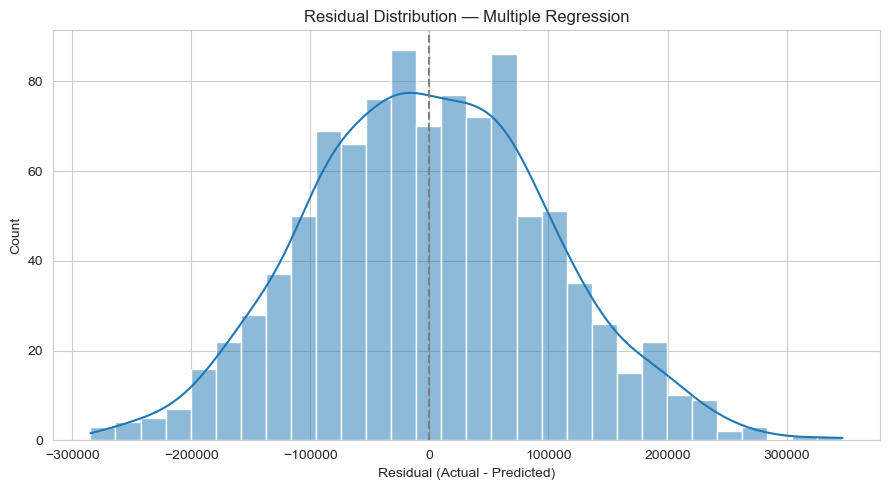

In [23]:
residuals = y_test_multi - y_pred_multi

plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.title('Residual Distribution — Multiple Regression')
plt.xlabel('Residual (Actual - Predicted)')
plt.axvline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

Observation Prompt — Part 4: Which model performed better, and by how much? Was
adding more features worth it? What does the shape of the residual histogram tell you about the
model's errors?

Multiple regression did better than simple regression. R² jumped from 0.40 to 0.92, and RMSE dropped from `~$272K` to `~$100K`, so the extra features were worth it. Residuals look roughly bell-shaped, so the model isn't consistently over- or under-guessing.

Part 5 — Bonus: Polynomial Regression (Optional)

Task 1: Using only Avg. Area Income, create degree-2 polynomial features

In [24]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

Task 2: Split, fit a LinearRegression model on the polynomial features, and calculate its R² score.

In [25]:
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly, y, test_size=0.2, random_state=42
)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train_poly)
y_pred_poly = model_poly.predict(X_test_poly)

r2_poly = metrics.r2_score(y_test_poly, y_pred_poly)
print('Polynomial (degree 2) R2:', r2_poly)

Polynomial (degree 2) R2: 0.39693433424210744


Task 3: Compare this R² score to the simple linear regression R² from Part 2. Did the curve
improve the fit?

In [26]:
print('Simple Linear R2:   ', r2_simple)
print('Polynomial R2:      ', r2_poly)
print('Difference (poly - linear):', r2_poly - r2_simple)

Simple Linear R2:    0.39694865192619766
Polynomial R2:       0.39693433424210744
Difference (poly - linear): -1.4317684090214833e-05


Observation Prompt — Bonus: Did polynomial regression improve on simple linear
regression for this feature? What might explain the result either way?

Polynomial regression didn't improve it because R² barely changed (0.3969 → 0.3969). Income vs. price already looked roughly linear, so there was no real curve for the model to pick up on.